In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df = pd.read_csv(url)
df_copy=df.copy()

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
#convert categorical features 

In [5]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [10]:
df.dtypes

model_year               int64
origin                  object
fuel_type               object
drivetrain              object
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [9]:
df.dtypes[df.dtypes == 'object']

origin        object
fuel_type     object
drivetrain    object
dtype: object

In [14]:
categorical = df.dtypes[df.dtypes == 'object'].index
categorical 

Index(['origin', 'fuel_type', 'drivetrain'], dtype='object')

In [15]:
numerical = df.dtypes[df.dtypes != 'object'].index
numerical 

Index(['model_year', 'num_doors', 'engine_displacement', 'num_cylinders',
       'horsepower', 'vehicle_weight', 'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [20]:
#convert all categorical values to lower case and remove spaces
for c in categorical:
    df[c]=df[c].str.lower().str.replace(' ','_')

In [21]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,europe,gasoline,front-wheel_drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,europe,diesel,front-wheel_drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,asia,gasoline,front-wheel_drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,europe,gasoline,front-wheel_drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,usa,diesel,front-wheel_drive,3,2580,7,304.0,4510,17.5,31.0


In [59]:
categorical = df['num_doors', 'num']

Index(['origin', 'fuel_type', 'drivetrain'], dtype='object')

In [22]:
#check null values in numerical
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [23]:
#replace null with zeros
df = df.fillna(0)

In [24]:
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [28]:
df_clean = df.copy()

### split dataset

In [29]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [30]:
df_train = df_train.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

In [33]:
y_train = df_train.fuel_efficiency_mpg.values
y_full_train = df_full_train.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values

In [34]:
del df_train['fuel_efficiency_mpg']
del df_full_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [35]:
df_train.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration
0,2011,usa,gasoline,front-wheel_drive,4,2370,6,284.0,4280,19.0
1,2012,usa,diesel,all-wheel_drive,3,2460,6,288.0,4580,18.8
2,1985,europe,gasoline,all-wheel_drive,3,2070,6,230.0,4150,20.6
3,2005,europe,diesel,front-wheel_drive,5,2050,5,249.0,4120,0.0
4,2004,asia,gasoline,front-wheel_drive,2,2160,6,241.0,4020,17.9


## Question 1

In [72]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer

from sklearn.metrics import mean_squared_error

In [42]:
train_dicts = df_train.to_dict(orient='records')

In [43]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

In [44]:
dv.get_feature_names()

['acceleration',
 'drivetrain=all-wheel_drive',
 'drivetrain=front-wheel_drive',
 'drivetrain=rear-wheel_drive',
 'engine_displacement',
 'fuel_type=diesel',
 'fuel_type=gasoline',
 'fuel_type=hybrid',
 'horsepower',
 'model_year',
 'num_cylinders',
 'num_doors',
 'origin=asia',
 'origin=europe',
 'origin=usa',
 'vehicle_weight']

In [61]:
dt = DecisionTreeRegressor(max_depth=1)

dt.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=1)

In [62]:
# Replace feature name with exact name
from sklearn.tree import export_text
print(export_text(dt, feature_names=dv.get_feature_names()))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



### Ans:1 model_year is used for splitting data

## Question:2

In [78]:
train_dicts = df_train.to_dict(orient='records')
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

In [79]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestRegressor(n_estimators=10, n_jobs=-1, random_state=1)

In [82]:
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [84]:
y_pred = rf.predict(X_val)

In [85]:
rmse = mean_squared_error(y_val, y_pred, squared=False)
rmse

1.8392210851335953

### Ans:2 RMSE=1.839

## Question 3

In [94]:
# now check RF for different n_estimators
scores = []

for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)
    
    y_pred = rf.predict(X_val)
    rmse = mean_squared_error(y_val, y_pred, squared=False)
    
    scores.append((n, rmse.round(4)))

In [95]:
cols=['no_estimators', 'rmse']
df_scores= pd.DataFrame(scores, columns=cols)
df_scores

,no_estimators,rmse
0,10,1.8392
1,50,1.7729
2,100,1.7682
3,150,1.7677


### Ans:3 n_estimators=150 has minimum rmse as 1.767

## Question 4

In [100]:
scores = []

for d in [10,15,20,25]:
    for n in [10, 50, 100, 150]:
            rf = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=1)
            rf.fit(X_train, y_train)

            y_pred = rf.predict(X_val)
            rmse = mean_squared_error(y_val, y_pred, squared=False)
            scores.append((d,n,rmse))

In [101]:
cols=['max_depth', 'no_estimators', 'rmse']
df_scores= pd.DataFrame(scores, columns=cols)
df_scores

,max_depth,no_estimators,rmse
0,10,10,1.786430
1,10,50,1.748302
2,10,100,1.745137
3,10,150,1.744008
4,15,10,1.836676
5,15,50,1.772385
6,15,100,1.769205
7,15,150,1.767774
8,20,10,1.841211
9,20,50,1.772556


In [104]:
df_scores.groupby(['max_depth']).mean('rmse')

,no_estimators,rmse
max_depth,,
10,77.5,1.755969
15,77.5,1.786510
20,77.5,1.787242
25,77.5,1.788057


### Ans 4: max_depth = 10 has least mean rmse=1.756

## Question 5

In [109]:
#### Use steps from Q3 to train a random forest model

In [110]:
train_dicts = df_train.to_dict(orient='records')
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

In [111]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, n_estimators=10, n_jobs=-1, random_state=1)

In [112]:
importances = rf.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': dv.get_feature_names(),
    'Importance': importances
})

In [118]:
feature_importance_df.sort_values(by='Importance', ascending=False)

,Feature,Importance
9,model_year,0.295917
15,vehicle_weight,0.203420
6,fuel_type=gasoline,0.160713
8,horsepower,0.077732
4,engine_displacement,0.061682
0,acceleration,0.055387
14,origin=usa,0.042299
2,drivetrain=front-wheel_drive,0.020116
5,fuel_type=diesel,0.020037
11,num_doors,0.019322


In [131]:
slected_features = feature_importance_df[feature_importance_df['Feature'].isin(['vehicle_weight','horsepower','acceleration','engine_displacement'])]
slected_features

,Feature,Importance
0,acceleration,0.055387
4,engine_displacement,0.061682
8,horsepower,0.077732
15,vehicle_weight,0.203420


In [135]:
slected_features.sort_values(by='Importance', ascending=False)

,Feature,Importance
15,vehicle_weight,0.203420
8,horsepower,0.077732
4,engine_displacement,0.061682
0,acceleration,0.055387


### Ans:5 feature vehicle_weight has max importance

## Qustion 6

In [143]:
import xgboost as xgb

In [144]:
# For xgboost, we need to transform train data in a dtrain matrix before fitting model
features = list(dv.get_feature_names())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

#### eta=0.3

In [176]:
watchlist = [(dtrain, 'train'), (dval,'val')]

In [185]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [186]:
scores = {}

In [187]:
%%capture output

xgb_params = {
'eta': 0.3, 
'max_depth': 6,
'min_child_weight': 1,

'objective': 'reg:squarederror',
'eval_metric': 'rmse',
'nthread': 8,

'seed': 1,
'verbosity': 1,
}

# train model on above transformed datasets
model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, evals=watchlist)

In [188]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.3'

#### check with eta=0.1

In [189]:
xgb_params = {
'eta': 0.1, 
'max_depth': 6,
'min_child_weight': 1,

'objective': 'reg:squarederror',
'eval_metric': 'rmse',
'nthread': 8,

'seed': 1,
'verbosity': 1,
}

# train model on above transformed datasets
model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, evals=watchlist)

[0]	train-rmse:26.71116	val-rmse:26.69590
[5]	train-rmse:15.86865	val-rmse:15.86380
[10]	train-rmse:9.49428	val-rmse:9.49287
[15]	train-rmse:5.77711	val-rmse:5.78479
[20]	train-rmse:3.65658	val-rmse:3.69450
[25]	train-rmse:2.50247	val-rmse:2.58803
[30]	train-rmse:1.92509	val-rmse:2.06062
[35]	train-rmse:1.66240	val-rmse:1.83872
[40]	train-rmse:1.54528	val-rmse:1.75586
[45]	train-rmse:1.49106	val-rmse:1.72743
[50]	train-rmse:1.46013	val-rmse:1.72104
[55]	train-rmse:1.43971	val-rmse:1.71962
[60]	train-rmse:1.42499	val-rmse:1.71992
[65]	train-rmse:1.41135	val-rmse:1.72100
[70]	train-rmse:1.40055	val-rmse:1.72186
[75]	train-rmse:1.38761	val-rmse:1.72364
[80]	train-rmse:1.38122	val-rmse:1.72506
[85]	train-rmse:1.37126	val-rmse:1.72514
[90]	train-rmse:1.36147	val-rmse:1.72826
[95]	train-rmse:1.35305	val-rmse:1.72932
[100]	train-rmse:1.34067	val-rmse:1.73129
[105]	train-rmse:1.33319	val-rmse:1.73228
[110]	train-rmse:1.31415	val-rmse:1.73410
[115]	train-rmse:1.30407	val-rmse:1.73740
[120]	trai

In [190]:
%%capture output

xgb_params = {
'eta': 0.1, 
'max_depth': 6,
'min_child_weight': 1,

'objective': 'reg:squarederror',
'eval_metric': 'rmse',
'nthread': 8,

'seed': 1,
'verbosity': 1,
}

# train model on above transformed datasets
model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, evals=watchlist)

In [191]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.1'

In [192]:
scores

{'eta=0.3':     num_iter  train_rmse  val_rmse
 0          0    20.82754  20.82237
 1          5     3.89806   3.93093
 2         10     1.65517   1.84157
 3         15     1.48691   1.73815
 4         20     1.44328   1.73725
 5         25     1.39890   1.74399
 6         30     1.36533   1.74683
 7         35     1.32923   1.75473
 8         40     1.29143   1.76591
 9         45     1.25373   1.77444
 10        50     1.22649   1.77636
 11        55     1.19964   1.78080
 12        60     1.15740   1.79177
 13        65     1.11478   1.80412
 14        70     1.07960   1.81138
 15        75     1.05673   1.81347
 16        80     1.02948   1.81722
 17        85     1.00346   1.82238
 18        90     0.98040   1.82492
 19        95     0.95488   1.83219
 20       100     0.92871   1.83288
 21       105     0.90110   1.83782
 22       110     0.87815   1.84240
 23       115     0.86742   1.84521
 24       120     0.85312   1.84825
 25       125     0.83191   1.85154
 26       130    

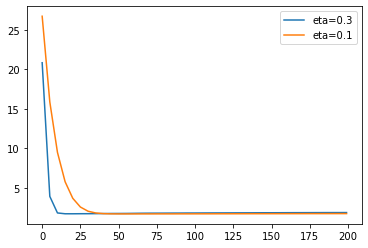

In [193]:
for eta, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_rmse, label=eta)

plt.legend()

### Ans:6 The blue line with eta=0.3 is better RMSE because it reaches the lowest RMSE much faster than eta=0.1.

In [198]:
# Train final model

In [199]:
%%capture output

xgb_params = {
'eta': 0.3, 
'max_depth': 6,
'min_child_weight': 1,

'objective': 'reg:squarederror',
'eval_metric': 'rmse',
'nthread': 8,

'seed': 1,
'verbosity': 1,
}

# train model on above transformed datasets
model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, evals=watchlist)

In [200]:
y_pred = model.predict(dval)
rmse = mean_squared_error(y_val, y_pred, squared=False)

In [201]:
rmse

1.8907217749151601